In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
os.makedirs("outputs", exist_ok=True) 
data = {
    "cap_shape": ["convex", "flat", "convex", "flat",
                  "bell", "convex", "bell", "flat"],
    "color": ["brown", "white", "yellow", "white",
              "brown", "yellow", "white", "brown"],
    "odor": ["almond", "foul", "none", "foul",
             "almond", "none", "foul", "almond"],
    "class": ["edible", "poisonous", "edible", "poisonous",
              "edible", "edible", "poisonous", "edible"]
}

df = pd.DataFrame(data)

print("MUSHROOM CLASSIFICATION DATASET")
print(df) 

MUSHROOM CLASSIFICATION DATASET
  cap_shape   color    odor      class
0    convex   brown  almond     edible
1      flat   white    foul  poisonous
2    convex  yellow    none     edible
3      flat   white    foul  poisonous
4      bell   brown  almond     edible
5    convex  yellow    none     edible
6      bell   white    foul  poisonous
7      flat   brown  almond     edible



CLASSIFICATION REPORT
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00         1
   poisonous       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2


MUSHROOM CLASSIFICATION RESULT
Predicted Category: edible


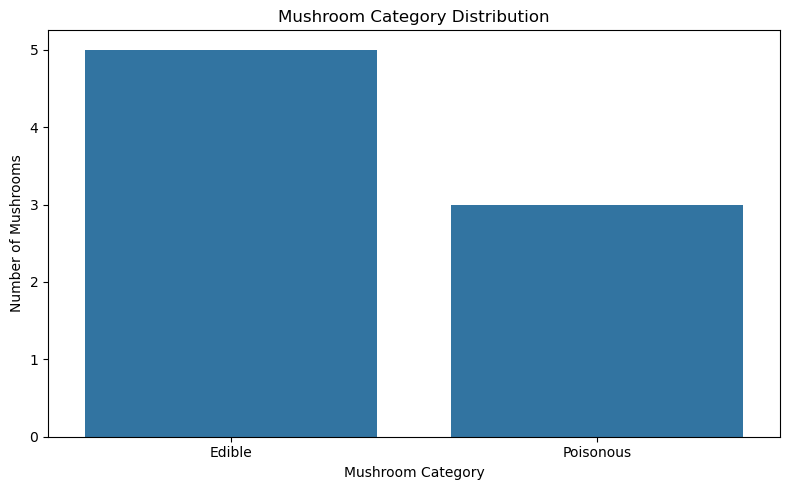

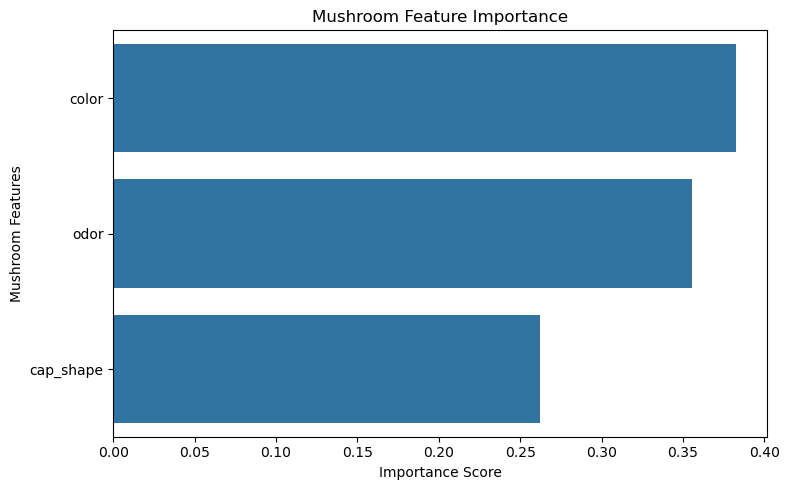

In [2]:
encoders = {}

for column in df.columns:
    encoder = LabelEncoder()
    df[column] = encoder.fit_transform(df[column])
    encoders[column] = encoder
X = df.drop("class", axis=1)
y = df["class"] 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    stratify=y
) 
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train) 
predictions = model.predict(X_test)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=encoders["class"].inverse_transform([0, 1]),
    zero_division=0
)) 
new_mushroom = pd.DataFrame([{
    "cap_shape": "convex",
    "color": "brown",
    "odor": "almond"
}])

for column in new_mushroom.columns:
    new_mushroom[column] = (
        encoders[column].transform(new_mushroom[column])
    )

prediction = model.predict(new_mushroom)

result = encoders["class"].inverse_transform(prediction)

probabilities = model.predict_proba(new_mushroom)[0]

print("\nMUSHROOM CLASSIFICATION RESULT")
print("Predicted Category:", result[0]) 

plt.figure(figsize=(8, 5))

sns.countplot(
    x="class",
    data=df,
    order=[encoders["class"].transform(["edible"])[0],
           encoders["class"].transform(["poisonous"])[0]]
)

plt.title("Mushroom Category Distribution")
plt.xlabel("Mushroom Category")
plt.ylabel("Number of Mushrooms")
plt.xticks(
    [0, 1],
    ["Edible", "Poisonous"]
)

plt.tight_layout()
plt.savefig("outputs/category_distribution.png")
plt.show()
plt.close() 
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Mushroom Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Mushroom Features")

plt.tight_layout()
plt.savefig("outputs/feature_importance.png")
plt.show()
plt.close() 

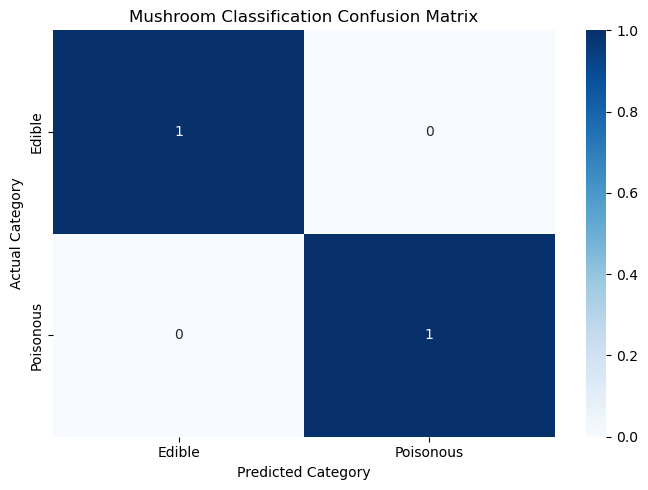

In [3]:
cm = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Edible", "Poisonous"],
    yticklabels=["Edible", "Poisonous"]
)

plt.title("Mushroom Classification Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()
plt.close() 

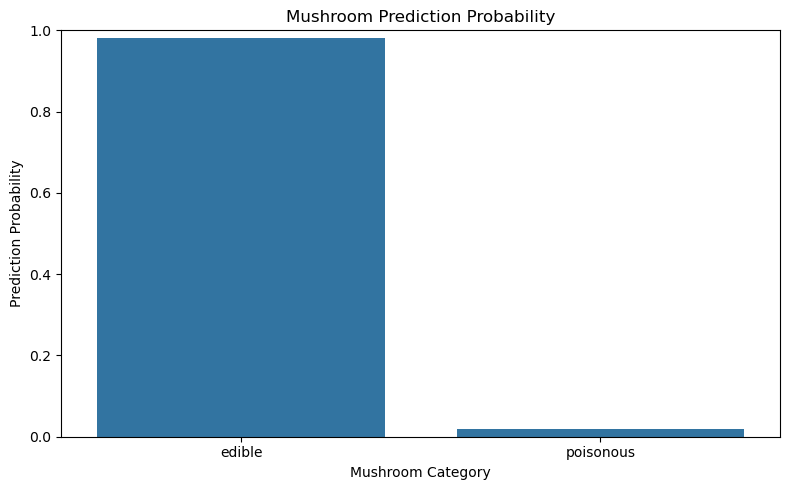


All Four Visualizations Saved Successfully!
Check the outputs folder.


In [4]:
class_names = encoders["class"].inverse_transform(
    model.classes_
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_names,
    y=probabilities
)

plt.title("Mushroom Prediction Probability")
plt.xlabel("Mushroom Category")
plt.ylabel("Prediction Probability")

plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("outputs/prediction_probability.png")
plt.show()
plt.close()

print("\nAll Four Visualizations Saved Successfully!")
print("Check the outputs folder.") 